# 06. 하나의 모델 사양을 Stellantis N.V.와 KAMP에 똑같이 적용 — 검사 예산 추천
사양(`br/spec.py`): 입력은 타점당 전류·전압·통전시간·가압력과 같은 식의 파생 3개(V·I·t, V/I, I/F). 정답은 날짜별 불량 개수만 쓴다.
날짜를 하나씩 빼고 학습한 뒤, 뺀 날짜의 타점에 점수를 매긴다. 주 모델은 PVC MLP로 미리 정했다.

- **Stellantis N.V.**: 숨긴 개별 정답으로 예산별 포착 불량 수를 채점한다(주 지표: 10% 예산의 무작위 대비 차이).
- **KAMP**: 일별 개수로 채점하고, 같은 예산 규칙으로 날짜별 추천 목록을 만든다. 복사 블록 행은 순위에서 빼고 `품질확인`으로 표시한다.

In [1]:
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import br
from br import spec as S, budget as B, plot as P
from wl.metrics import inclusion_prob, within_loc_auroc
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
DATA = {"polito": S.load_polito(), "kamp": S.load_kamp()}
SEEDS = range(5)
cache = br.RES / "same_model_scores.pkl"
sc = pd.read_pickle(cache) if cache.exists() else pd.DataFrame()
done = set(map(tuple, sc[["data", "model", "seed"]].drop_duplicates().values)) if len(sc) else set()
for ds, (X, day, cnt, y, blk) in DATA.items():
    for m in S.MODELS:
        for s in (SEEDS if m != "고정 불량률" else [0]):
            if (ds, m, s) in done:
                continue
            t = time.time()
            score, prob = S.lodo(m, X, day, cnt, s)
            sc = pd.concat([sc, pd.DataFrame({"data": ds, "model": m, "seed": s, "row": np.arange(len(day)),
                                              "score": score, "prob": prob})], ignore_index=True)
            sc.to_pickle(cache)
            print(f"{ds:6s} {m:12s} seed={s}  {time.time()-t:5.1f}초", flush=True)
print("완료", sc.shape)

polito 고정 불량률       seed=0    0.0초


polito AE (정답 미사용)  seed=0    6.0초


polito AE (정답 미사용)  seed=1    5.0초


polito AE (정답 미사용)  seed=2    5.1초


polito AE (정답 미사용)  seed=3    5.1초


polito AE (정답 미사용)  seed=4    5.1초


... (33 outputs left out)

kamp   집계 로지스틱      seed=2    1.4초


kamp   집계 로지스틱      seed=3    1.4초


kamp   집계 로지스틱      seed=4    1.4초


완료 (292215, 6)


## 1. 일별 불량 개수 MAE (날짜 하나 빼고 학습 → 그 날짜 추정)

In [2]:
rows = []
for (ds, m, s), g in sc.groupby(["data", "model", "seed"]):
    X, day, cnt, y, blk = DATA[ds]
    ok = ~np.isnan(g.prob.values)
    pred = pd.Series(g.prob.values[ok]).groupby(day[ok]).sum()
    rows.append(dict(데이터=ds, 모델=m, seed=s, MAE=(pred - cnt.loc[pred.index]).abs().mean()))
mae = pd.DataFrame(rows).groupby(["데이터", "모델"]).MAE.agg(["mean", "min", "max"]).round(2)
mae.to_csv(br.RES / "same_model_count_mae.csv", encoding="utf-8-sig")
mae

mean   min   max
데이터    모델                           
kamp   AE (정답 미사용)  2.19  2.19  2.19
       PVC MLP      2.84  2.46  3.23
       고정 불량률       2.19  2.19  2.19
       비율맞춤 MLP     2.61  2.59  2.62
       집계 로지스틱      1.69  1.69  1.69
polito AE (정답 미사용)  2.47  2.47  2.47
       PVC MLP      2.60  2.29  2.98
       고정 불량률       2.47  2.47  2.47
       비율맞춤 MLP     3.10  3.00  3.30
       집계 로지스틱      2.72  2.72  2.72

## 2. Stellantis N.V. 검사 예산 — 숨긴 개별 정답으로 채점 (날짜별 상위 b%)

In [3]:
X, pday, pcnt, py, _ = DATA["polito"]
NPOS = int(py.sum())
pol = sc[sc.data == "polito"].sort_values(["model", "seed", "row"])
curves = [B.curve(py, g.score.values, pday).assign(model=m, seed=s) for (m, s), g in pol.groupby(["model", "seed"]) if m != "고정 불량률"]
curves.append(B.random_curve(py, pday).assign(model="무작위 선택(기대값)", seed=0))
cv = pd.concat(curves, ignore_index=True)
cv.to_csv(br.RES / "same_model_polito_curves.csv", index=False, encoding="utf-8-sig")
agg = cv.groupby(["model", "budget"]).agg(caught=("caught", "mean"), lo=("caught", "min"), hi=("caught", "max"),
                                         inspected=("inspected", "mean")).reset_index()
t = agg[agg.budget.isin([.05, .1, .2, .3, .5])].pivot(index="model", columns="budget", values="caught")
t.columns = [f"{int(round(c*100))}%" for c in t.columns]
print(f"Stellantis N.V. 1,976건 중 불량 {NPOS}개 — 포착 수 (5시드 평균)")
t.sort_values("10%", ascending=False).round(1)

Stellantis N.V. 1,976건 중 불량 79개 — 포착 수 (5시드 평균)


,5%,10%,20%,30%,50%
model,,,,,
비율맞춤 MLP,14.4,23.6,32.8,39.2,52.6
PVC MLP,11.0,22.8,40.2,49.2,61.4
집계 로지스틱,6.0,13.0,16.0,21.0,38.0
AE (정답 미사용),5.0,10.6,19.0,28.2,47.4
무작위 선택(기대값),4.9,8.6,16.0,24.4,40.1


## 3. 개수 연동 예산 — 날짜마다 (추정 불량 수 × m)개 검사
추정 불량 수는 같은 모델의 그날 확률 합(AE는 학습 날짜의 평균 불량률 × 타점 수).

In [4]:
def count_budget_hits(y, score, prob, day, m):
    ud, gi = np.unique(day, return_inverse=True)
    n = np.bincount(gi)
    k = np.minimum(np.ceil(m * np.bincount(gi, weights=prob) - 1e-9), n)
    p = inclusion_prob(score, k.astype(float), gi)
    return k.sum(), (p * y).sum(), (k / n * np.bincount(gi, weights=y)).sum()   # 검사 수, 포착, 같은 수 무작위 기대값
rows = []
for (m, s), g in pol.groupby(["model", "seed"]):
    if m == "고정 불량률":
        continue
    for mult in (2.5, 5, 10):
        k, h, r = count_budget_hits(py, g.score.values, g.prob.values, pday, mult)
        rows.append(dict(모델=m, seed=s, 배수=mult, 검사수=k, 검사비율=k / len(py), 포착=h, 같은수무작위=r))
cb = pd.DataFrame(rows).groupby(["모델", "배수"])[["검사수", "검사비율", "포착", "같은수무작위"]].mean()
cb.round(2)

검사수  검사비율    포착  같은수무작위
모델          배수                              
AE (정답 미사용) 2.5    210.0  0.11  10.8    8.37
            5.0    408.0  0.21  18.4   15.51
            10.0   807.0  0.41  35.6   30.88
PVC MLP     2.5    211.8  0.11  23.0    8.41
            5.0    412.0  0.21  38.6   16.38
            10.0   789.0  0.40  51.8   31.40
비율맞춤 MLP    2.5    304.0  0.15  29.6   12.72
            5.0    595.2  0.30  38.2   24.17
            10.0  1163.8  0.59  58.8   47.57
집계 로지스틱     2.5    230.0  0.12  13.0    9.59
            5.0    446.0  0.23  18.0   18.85
            10.0   848.0  0.43  32.0   36.31

## 4. 주 지표 — 10% 예산 포착률의 무작위 대비 차이 (차체 복원추출 5,000회), 위치 효과 점검

In [5]:
pbody = wldata.load_polito().body.values; ploc = wldata.load_polito()["loc"].values
rng = np.random.default_rng(0); ub = np.unique(pbody)
Wb = np.stack([np.bincount(d_, minlength=len(ub)) for d_ in rng.integers(0, len(ub), (5000, len(ub)))])[:, np.searchsorted(ub, pbody)]
ud, gi = np.unique(pday, return_inverse=True)
def ci(a): return f"{np.mean(a):+.3f} [{np.quantile(a, .025):+.3f}, {np.quantile(a, .975):+.3f}]"
rows = []
for b in (0.05, 0.10, 0.20):
    k = np.ceil(b * np.bincount(gi) - 1e-9)
    p_rand = (k / np.bincount(gi))[gi]
    r_rand = (Wb @ (p_rand * py)) / (Wb @ py)
    for m in S.MODELS[1:]:
        ps = np.mean([inclusion_prob(g.score.values, k, gi) for _, g in pol[pol.model == m].groupby("seed")], 0)
        d_ = (Wb @ (ps * py)) / (Wb @ py) - r_rand
        rows.append({"예산": f"{int(b*100)}%", "모델": m, "포착률": f"{(ps*py).sum()/NPOS:.3f}", "무작위 대비 [95%]": ci(d_),
                     "차이≤0 비율": f"{(d_ <= 0).mean():.3f}"})
main = pd.DataFrame(rows); main.to_csv(br.RES / "same_model_main_metric.csv", index=False, encoding="utf-8-sig")
display(main)
grp = np.char.add(pday.astype(str), "_" + ploc.astype(str))
print("같은 날·같은 위치 안 AUROC (0.5 = 무작위):",
      {m: round(np.mean([within_loc_auroc(py, g.score.values, grp) for _, g in pol[pol.model == m].groupby("seed")]), 3) for m in S.MODELS[1:]})

,예산,모델,포착률,무작위 대비 [95%],차이≤0 비율
0,5%,AE (정답 미사용),0.063,"+0.001 [-0.027, +0.038]",0.517
1,5%,PVC MLP,0.139,"+0.074 [+0.006, +0.137]",0.015
2,5%,비율맞춤 MLP,0.182,"+0.116 [+0.040, +0.184]",0.003
3,5%,집계 로지스틱,0.076,"+0.011 [-0.048, +0.065]",0.350
4,10%,AE (정답 미사용),0.134,"+0.026 [-0.025, +0.086]",0.172
5,10%,PVC MLP,0.289,"+0.175 [+0.077, +0.255]",0.001
6,10%,비율맞춤 MLP,0.299,"+0.185 [+0.069, +0.284]",0.002
7,10%,집계 로지스틱,0.165,"+0.051 [-0.047, +0.155]",0.175
8,20%,AE (정답 미사용),0.241,"+0.038 [-0.021, +0.104]",0.107
9,20%,PVC MLP,0.509,"+0.301 [+0.176, +0.396]",0.000


같은 날·같은 위치 안 AUROC (0.5 = 무작위): {'AE (정답 미사용)': np.float64(0.582), 'PVC MLP': np.float64(0.564), '비율맞춤 MLP': np.float64(0.539), '집계 로지스틱': np.float64(0.515)}


## 5. 그림 — Stellantis N.V. 검사 예산 곡선 (KAMP와 같은 모델)

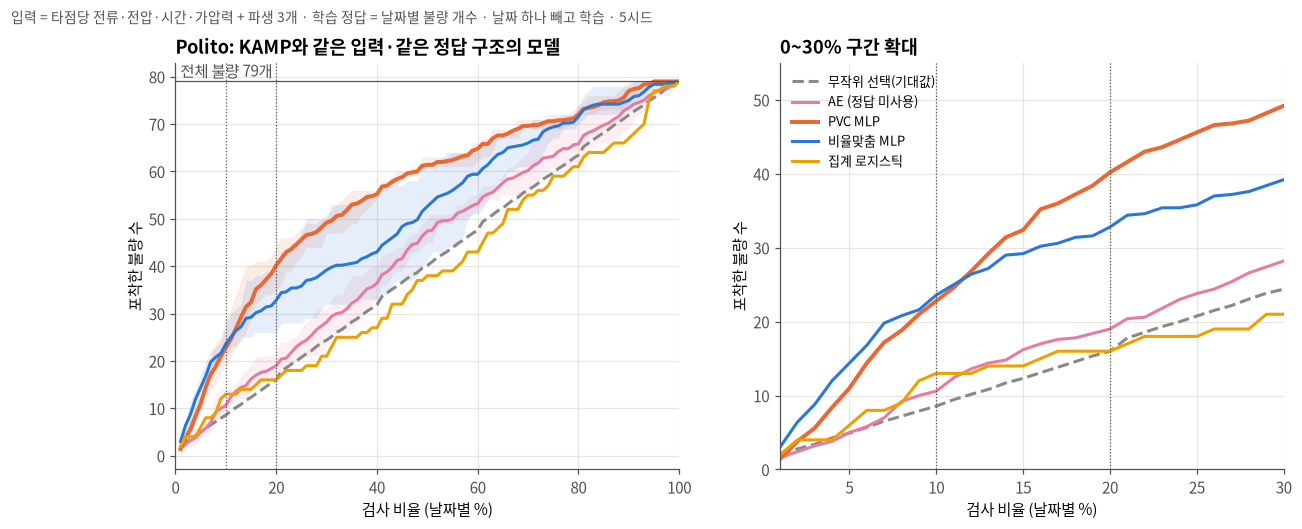

In [6]:
KEY = [("무작위 선택(기대값)", P.GRAY, "--"), ("AE (정답 미사용)", P.PAL[4], "-"), ("PVC MLP", P.PAL[1], "-"),
       ("비율맞춤 MLP", P.PAL[0], "-"), ("집계 로지스틱", P.PAL[3], "-")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for lab, col, ls in KEY:
    a = agg[agg.model == lab]; x = a.budget * 100
    for ax in axes:
        ax.plot(x, a.caught, ls, color=col, label=lab, lw=2.6 if lab == S.PRIMARY else 2)
    axes[0].fill_between(x, a.lo, a.hi, color=col, alpha=.12, lw=0)
axes[0].axhline(NPOS, color=P.INK2, lw=.8); axes[0].text(1, NPOS + 1, f"전체 불량 {NPOS}개", color=P.INK2)
axes[0].set_xlim(0, 100); axes[1].set_xlim(1, 30); axes[1].set_ylim(0, 55)
for ax in axes:
    ax.set_xlabel("검사 비율 (날짜별 %)"); ax.set_ylabel("포착한 불량 수")
    for b in (10, 20): ax.axvline(b, color=P.INK2, lw=.8, ls=":")
axes[0].set_title("Stellantis N.V.: KAMP와 같은 입력·같은 정답 구조의 모델", loc="left", fontweight="bold")
axes[1].set_title("0~30% 구간 확대", loc="left", fontweight="bold"); axes[1].legend(loc="upper left", fontsize=8.5)
fig.suptitle("입력 = 타점당 전류·전압·시간·가압력 + 파생 3개 · 학습 정답 = 날짜별 불량 개수 · 날짜 하나 빼고 학습 · 5시드",
             x=0.01, ha="left", color=P.INK2, fontsize=9)
P.save(fig, "08_same_model_polito_budget"); plt.show()

## 6. KAMP — 날짜별 실제 불량 vs 같은 모델의 추정 (날짜 하나 빼고 학습)

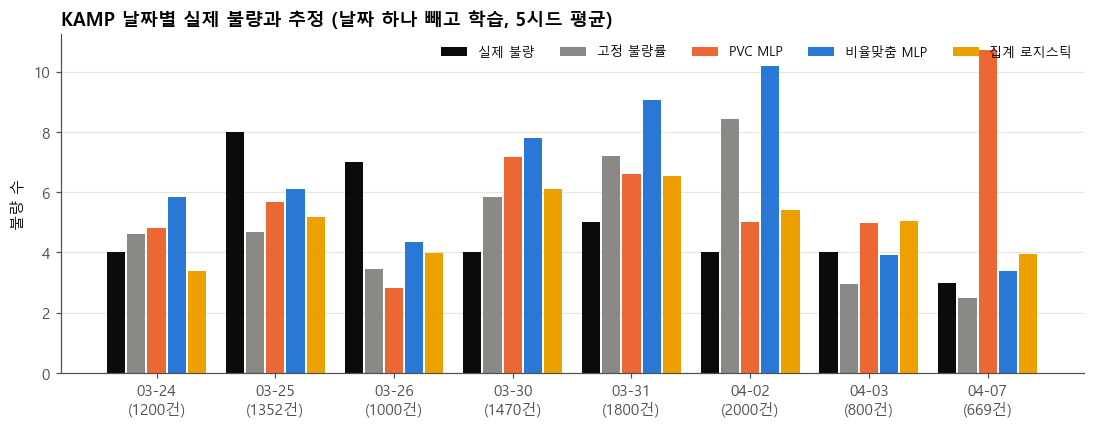

In [7]:
X, kday, kcnt, _, kblk = DATA["kamp"]
kam = sc[sc.data == "kamp"]
est = kam.groupby(["model", "seed"]).apply(lambda g: pd.Series(g.prob.values).groupby(kday).sum(min_count=1)).groupby("model").mean()
lab_days = [d for d in kcnt.index if not np.isnan(kcnt[d])]
fig, ax = plt.subplots(figsize=(12, 4))
show = [("고정 불량률", P.GRAY), ("PVC MLP", P.PAL[1]), ("비율맞춤 MLP", P.PAL[0]), ("집계 로지스틱", P.PAL[3])]
w = .17; x = np.arange(len(lab_days))
ax.bar(x - 2 * w, kcnt.loc[lab_days].values, w * .9, color=P.INK, label="실제 불량")
for i, (m, col) in enumerate(show):
    ax.bar(x + (i - 1) * w, est.loc[m, lab_days].values, w * .9, color=col, label=m)
nday = pd.Series(kday).value_counts()
ax.set_xticks(x); ax.set_xticklabels([f"{d[5:]}\n({nday[d]}건)" for d in lab_days])
ax.set_ylabel("불량 수"); ax.grid(axis="x", visible=False); ax.legend(ncol=5, fontsize=8.5, loc="upper right")
ax.set_title("KAMP 날짜별 실제 불량과 추정 (날짜 하나 빼고 학습, 5시드 평균)", loc="left", fontweight="bold")
P.save(fig, "09_same_model_kamp_counts"); plt.show()

## 7. KAMP 추천 목록 — 주 모델(PVC MLP), 5시드 평균 점수
날짜마다 복사 블록을 뺀 타점에서 순위를 매기고, 비율 예산과 개수 연동 예산의 추천 여부를 표시한다.
정답 없는 3/27은 8일 전체로 학습한 모델로 점수를 매긴다.

In [8]:
from scipy.special import expit
pri = kam[kam.model == S.PRIMARY].groupby("row")[["score", "prob"]].mean()
score, prob = pri.score.values.copy(), pri.prob.values.copy()
miss = np.isnan(score)
if miss.any():
    lab = np.isin(kday, lab_days); ubd, bag = np.unique(kday[lab], return_inverse=True)
    zs = [S.fit_score(S.PRIMARY, X, bag, kcnt.loc[ubd].values.astype(int), lab, miss, s) for s in SEEDS]
    score[miss] = np.mean([z[0] for z in zs], 0); prob[miss] = np.mean([z[1] for z in zs], 0)
K = pd.DataFrame({"date": kday, "row": np.arange(len(kday)), "block": kblk, "위험점수": score, "불량확률": prob})
K["상태"] = np.where(K.block, "품질확인(복사 블록)", "순위 부여")
r = K[~K.block].groupby("date").위험점수.rank(ascending=False, method="first")
K.loc[~K.block, "일내순위"] = r
K["일내타점수"] = K[~K.block].groupby("date").row.transform("size")
for b in (0.05, 0.10, 0.20):
    K[f"추천_{int(b*100)}%"] = K.일내순위 <= np.ceil(b * K.일내타점수)
est_day = K[~K.block].groupby("date").불량확률.sum()
for mult in (2.5, 5, 10):
    K[f"추천_{mult}배"] = K.일내순위 <= np.ceil(mult * K.date.map(est_day))
raw = DATA["kamp"][0]
K = pd.concat([K, raw[["cur", "vol", "time", "force"]].reset_index(drop=True)], axis=1)
K.to_csv(br.RES / "kamp_recommendations.csv", index=False, encoding="utf-8-sig")
summ = K[~K.block].groupby("date").agg(타점수=("row", "size"), 추정불량=("불량확률", "sum"),
                                         **{c: (c, "sum") for c in K.columns if c.startswith("추천_")})
summ["실제불량"] = kcnt.reindex(summ.index).values
summ.round(1)

,타점수,추정불량,추천_5%,추천_10%,추천_20%,추천_2.5배,추천_5배,추천_10배,실제불량
date,,,,,,,,,
2020-03-24,1200,4.8,60,120,240,13,25,49,4.0
2020-03-25,1061,5.7,54,107,213,15,29,57,8.0
2020-03-26,1000,2.8,50,100,200,8,15,29,7.0
2020-03-27,1357,6.0,68,136,272,15,30,60,NaN
2020-03-30,1470,7.2,74,147,294,18,36,72,4.0
2020-03-31,1509,6.6,76,151,302,17,34,67,5.0
2020-04-02,2000,5.0,100,200,400,13,25,50,4.0
2020-04-03,509,5.0,26,51,102,13,25,50,4.0
2020-04-07,669,10.7,34,67,134,27,54,108,3.0
